BERT-Based Malicious URL Detection — Kaggle
Independent reimplementation of the URL-string experiment in Su & Su (2023), Sensors 23(20), 8499. Original paper: https://doi.org/10.3390/s23208499

Paper settings retained: bert-base-cased, max length 128, learning rate 1e-5, batch size 16, 80/20 outer train/test split, four classes. Practical change: default 10,000 URLs per class and 3 epochs (paper considered 10/20/30). An extra validation split is taken from training data for epoch monitoring. This is not an exact reproduction.

In [2]:
# Imports
import os, glob, json, random
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding, Trainer, TrainingArguments
from torch.utils.data import Dataset

In [11]:
# settings

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
MODEL_NAME = "bert-base-cased"
MAX_LENGTH = 128
SAMPLES_PER_CLASS = None  # Set to None to use all available rows
EPOCHS = 3                  # Paper investigated 10, 20, 30
BATCH_SIZE = 16
LEARNING_RATE = 1e-5
OUT = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('/content')
print('Torch:', torch.__version__, 'GPU:', torch.cuda.is_available())
assert torch.cuda.is_available(), 'Enable a GPU accelerator in Kaggle settings.'


Torch: 2.11.0+cu130 GPU: True


In [12]:
# read the dataset

paths = list(Path('/kaggle/input').rglob('*.csv'))
print('Available CSV files:', [str(p) for p in paths[:20]])

if not paths:
    raise FileNotFoundError('Attach Kaggle dataset sid321axn/malicious-urls-dataset via Add Input, then rerun.')
# Prefer the expected file name when more than one dataset is attached.
choices = [p for p in paths if 'malicious_phish' in p.name.lower()]

if not choices:
    choices = [p for p in paths if 'malicious' in str(p).lower()]
if not choices:
    raise FileNotFoundError('Cannot identify malicious URLs CSV. Review printed paths and specify csv_path manually.')
    
csv_path = choices[0]
df = pd.read_csv(csv_path)

print('Reading:', csv_path)
print('Columns:', df.columns.tolist(), 'Rows:', len(df))

df.columns = [str(c).strip().lower() for c in df.columns]
assert {'url', 'type'}.issubset(df.columns), 'Expected columns url and type; inspect dataset columns.'

df = df[['url', 'type']].dropna().copy()
df['url'] = df['url'].astype(str).str.strip()
df['type'] = df['type'].astype(str).str.strip().str.lower()
labels = ['benign', 'defacement', 'phishing', 'malware']
df = df[df['type'].isin(labels) & df['url'].ne('')]

Available CSV files: ['/kaggle/input/datasets/sid321axn/malicious-urls-dataset/malicious_phish.csv']
Reading: /kaggle/input/datasets/sid321axn/malicious-urls-dataset/malicious_phish.csv
Columns: ['url', 'type'] Rows: 651191


In [13]:
# Remove duplicated URLs, including contradictory labels.
df = df.drop_duplicates(subset='url', keep=False).reset_index(drop=True)
print('After cleaning:', len(df))
print(df['type'].value_counts())

# select 100,000 URLs while preserving the original class proportions
df = df.sample(n=100_000, random_state=SEED).reset_index(drop=True)
    
df['label'] = df['type'].map({x:i for i,x in enumerate(labels)})
print('Selected examples:', len(df), df['type'].value_counts().to_dict())

After cleaning: 638912
type
benign        428051
defacement     94587
phishing       94068
malware        22206
Name: count, dtype: int64
Selected examples: 100000 {'benign': 66681, 'phishing': 14999, 'defacement': 14857, 'malware': 3463}


In [14]:
# data splits and BERT tokenization

train_pool, test_df = train_test_split(df, test_size=0.20, stratify=df['label'], random_state=SEED)
train_df, val_df = train_test_split(train_pool, test_size=0.10, stratify=train_pool['label'], random_state=SEED)
print('Train:', len(train_df), 'Validation:', len(val_df), 'Test:', len(test_df))

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
class URLDataset(Dataset):
    def __init__(self, frame):
        self.encodings = tokenizer(frame['url'].tolist(), truncation=True, max_length=MAX_LENGTH)
        self.labels = frame['label'].astype(int).tolist()
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        return {**{key: val[i] for key, val in self.encodings.items()}, 'labels': self.labels[i]}
train_ds, val_ds, test_ds = map(URLDataset, (train_df, val_df, test_df))
collator = DataCollatorWithPadding(tokenizer=tokenizer)

Train: 72000 Validation: 8000 Test: 20000


In [15]:
# train bert-base-cased

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=4, id2label={i:x for i,x in enumerate(labels)}, label2id={x:i for i,x in enumerate(labels)}
)

def compute_metrics(p):
    preds = np.argmax(p.predictions, axis=-1)
    precision, recall, f1, _ = precision_recall_fscore_support(p.label_ids, preds, average='macro', zero_division=0)
    return {'accuracy': accuracy_score(p.label_ids, preds), 'precision_macro': precision, 'recall_macro': recall, 'f1_macro': f1}
args = TrainingArguments(
    output_dir=str(OUT/'bert_url_checkpoints'),
    num_train_epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=32,
    eval_strategy='epoch',
    save_strategy='no',
    logging_strategy='epoch',
    report_to='none',
    fp16=True,
    disable_tqdm=True,
    seed=SEED,
    dataloader_num_workers=2,
)

trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                  processing_class=tokenizer, data_collator=collator, compute_metrics=compute_metrics)

print('Training started...')
trainer.train()
print('Training finished.')

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Training started...


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


{'loss': '0.333', 'grad_norm': '15.69', 'learning_rate': '6.668e-06', 'epoch': '1'}
{'eval_loss': '0.2183', 'eval_accuracy': '0.9714', 'eval_precision_macro': '0.9584', 'eval_recall_macro': '0.9466', 'eval_f1_macro': '0.9523', 'eval_runtime': '32.69', 'eval_samples_per_second': '244.7', 'eval_steps_per_second': '3.823', 'epoch': '1'}


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


{'loss': '0.1582', 'grad_norm': '13.53', 'learning_rate': '3.335e-06', 'epoch': '2'}
{'eval_loss': '0.215', 'eval_accuracy': '0.9741', 'eval_precision_macro': '0.9597', 'eval_recall_macro': '0.9554', 'eval_f1_macro': '0.9573', 'eval_runtime': '32.94', 'eval_samples_per_second': '242.9', 'eval_steps_per_second': '3.795', 'epoch': '2'}


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


{'loss': '0.1124', 'grad_norm': '14.09', 'learning_rate': '1.481e-09', 'epoch': '3'}
{'eval_loss': '0.2054', 'eval_accuracy': '0.978', 'eval_precision_macro': '0.9732', 'eval_recall_macro': '0.9593', 'eval_f1_macro': '0.9658', 'eval_runtime': '32.83', 'eval_samples_per_second': '243.7', 'eval_steps_per_second': '3.807', 'epoch': '3'}
{'train_runtime': '2621', 'train_samples_per_second': '82.42', 'train_steps_per_second': '2.575', 'train_loss': '0.2012', 'epoch': '3'}
Training finished.


In [16]:
# evaluate only once on held-out test

pred_output = trainer.predict(test_ds)
y_true = pred_output.label_ids
y_pred = np.argmax(pred_output.predictions, axis=-1)
accuracy = accuracy_score(y_true, y_pred)
precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)

print(classification_report(y_true, y_pred, target_names=labels, zero_division=0))

print('Confusion matrix (rows=true, columns=predicted):', confusion_matrix(y_true, y_pred))

metrics = pd.DataFrame([{
    'model': MODEL_NAME, 'dataset': 'sid321axn/malicious-urls-dataset',
    'classes': ','.join(labels), 'samples_per_class': SAMPLES_PER_CLASS or 'all',
    'train_examples': len(train_df), 'validation_examples':len(val_df), 'test_examples':len(test_df),
    'epochs': EPOCHS, 'batch_size': BATCH_SIZE, 'learning_rate': LEARNING_RATE,
    'max_length':MAX_LENGTH, 'accuracy':accuracy, 'precision_macro':precision,
    'recall_macro':recall, 'f1_macro':f1,
    'method': 'independent reimplementation; 80/20 outer split and inner validation'
}])

file = OUT/'BERT_URL_metrics_full.csv'
metrics.to_csv(file, index=False)
confusion_file = OUT/'BERT_URL_confusion_matrix_full.csv'
pd.DataFrame(confusion_matrix(y_true,y_pred),index=labels,columns=labels).to_csv(confusion_file)
display(metrics)
print('Metrics saved:',file)
print('Confusion matrix saved:',confusion_file)

trainer.save_model(str(OUT/'bert_url_model_full'))

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


              precision    recall  f1-score   support

      benign       0.99      0.99      0.99     13336
  defacement       0.98      1.00      0.99      2971
    phishing       0.92      0.94      0.93      3000
     malware       0.99      0.90      0.94       693

    accuracy                           0.98     20000
   macro avg       0.97      0.96      0.96     20000
weighted avg       0.98      0.98      0.98     20000

Confusion matrix (rows=true, columns=predicted): [[13153     2   179     2]
 [    2  2963     5     1]
 [  138    46  2811     5]
 [    6    10    50   627]]


,model,dataset,classes,samples_per_class,train_examples,validation_examples,test_examples,epochs,batch_size,learning_rate,max_length,accuracy,precision_macro,recall_macro,f1_macro,method
0,bert-base-cased,sid321axn/malicious-urls-dataset,"benign,defacement,phishing,malware",all,72000,8000,20000,3,16,0.00001,128,0.9777,0.970094,0.956337,0.962734,independent reimplementation; 80/20 outer spli...


Metrics saved: /kaggle/working/BERT_URL_metrics_full.csv
Confusion matrix saved: /kaggle/working/BERT_URL_confusion_matrix_full.csv


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

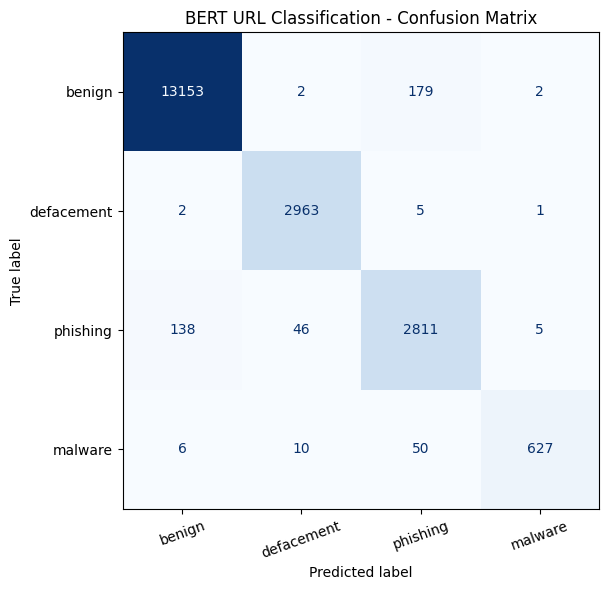

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_names = ["benign", "defacement", "phishing", "malware"]

cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)

plt.title("BERT URL Classification - Confusion Matrix")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig("/kaggle/working/BERT_URL_confusion_matrix_full.png", dpi=300, bbox_inches="tight")
plt.show()

In [18]:
import shutil
from pathlib import Path
from IPython.display import FileLink

model_path = Path("/kaggle/working/bert_url_model")

# Compress the previous model into a ZIP archive
zip_path = shutil.make_archive(
    "/kaggle/working/bert_url_model_40k",
    "zip",
    root_dir=model_path.parent,
    base_dir=model_path.name
)

print("Saved:", zip_path)
display(FileLink(zip_path))

Saved: /kaggle/working/bert_url_model_40k.zip


/kaggle/working/bert_url_model_40k.zip

In [19]:
zip_path = shutil.make_archive(
    "/kaggle/working/bert_url_model_100k",
    "zip",
    root_dir="/kaggle/working",
    base_dir="bert_url_model_full"
)

print("Saved:", zip_path)
display(FileLink(zip_path))

Saved: /kaggle/working/bert_url_model_100k.zip


/kaggle/working/bert_url_model_100k.zip